# Student Success Signals: A Data Quality & Learning Habits Audit

**WeIntern AIML Internship | Week 1 | Tasks 1-3**

## Project purpose
Explore how attendance, study time, assignment marks, and midterm marks are associated with final academic scores. The aim is to practise data handling and evidence-based reporting, not to build a machine-learning model.

> **Data transparency:** This project uses a simulated dataset generated for practice. It is not collected from real students and must not be used to make real student-level decisions. The raw file deliberately includes missing values, duplicate rows, inconsistent category labels, and invalid numeric values so the cleaning workflow can be demonstrated.

### Questions
1. How are final scores distributed?
2. How are attendance and study hours associated with final scores?
3. Do final-score distributions vary between students who report extra activities?
4. Which numeric fields have the strongest linear relationships?
5. What low-risk support actions could an education team consider, subject to validation on real data?

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Support running from either the repository root or the notebooks/ folder.
CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in CANDIDATES if (p / "data/raw/student_performance_raw.csv").exists()), Path.cwd())
DATA_RAW = PROJECT_ROOT / "data/raw/student_performance_raw.csv"
DATA_CLEAN = PROJECT_ROOT / "data/cleaned/student_performance_cleaned.csv"
CHART_DIR = PROJECT_ROOT / "outputs/charts"
TABLE_DIR = PROJECT_ROOT / "outputs/tables"
REPORT_DIR = PROJECT_ROOT / "outputs/reports"
for folder in [DATA_CLEAN.parent, CHART_DIR, TABLE_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from helper_scripts import normalize_gender, normalize_yes_no, normalize_parental_education, set_out_of_range_to_missing

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 160
pd.set_option("display.max_columns", 30)
print(f"Project root: {PROJECT_ROOT}")

Project root: /mnt/data/aiml-week1-student-success


## 1. Load and inspect the raw dataset
We keep the original CSV unchanged. The first step is to inspect the data before choosing any cleaning rules.

In [2]:
raw_df = pd.read_csv(DATA_RAW)
print("First five rows:")
display(raw_df.head())
print("Last five rows:")
display(raw_df.tail())
print(f"\nShape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print("\nColumn information:")
raw_df.info()

First five rows:


,Student_ID,Gender,Age,Attendance_Percentage,Study_Hours_Per_Week,Assignment_Score,Midterm_Score,Final_Score,Parental_Education,Internet_Access,Extra_Activities
0,10001,Female,18.0,87.2,5.3,80.5,97.8,79.4,Master's,No,n
1,10002,Female,22.0,85.9,12.9,87.8,92.6,92.4,High School,No,Yes
2,10003,Male,19.0,88.3,19.2,80.4,93.6,81.3,Bachelor's,Yes,Yes
3,10004,other,18.0,99.0,12.1,78.1,94.8,71.1,High School,Yes,No
4,10005,Male,19.0,88.1,18.8,93.6,100.0,81.2,Bachelor's,No,No


Last five rows:


,Student_ID,Gender,Age,Attendance_Percentage,Study_Hours_Per_Week,Assignment_Score,Midterm_Score,Final_Score,Parental_Education,Internet_Access,Extra_Activities
1207,10004,other,18.0,99.0,12.1,78.1,94.8,71.1,High School,Yes,No
1208,10619,Female,19.0,80.2,9.4,79.1,87.4,79.0,Doctorate,NO,Yes
1209,11041,M,15.0,99.6,10.4,NaN,98.8,82.1,Master's,Yes,Yes
1210,10961,Male,15.0,73.1,14.8,73.5,83.3,65.4,Bachelor's,Yes,Y
1211,10471,Female,19.0,74.5,6.0,69.4,78.9,71.9,OTHER,Y,No



Shape: 1,212 rows x 11 columns

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             1212 non-null   int64  
 1   Gender                 1194 non-null   object 
 2   Age                    1201 non-null   float64
 3   Attendance_Percentage  1172 non-null   float64
 4   Study_Hours_Per_Week   1180 non-null   float64
 5   Assignment_Score       1183 non-null   float64
 6   Midterm_Score          1185 non-null   float64
 7   Final_Score            1198 non-null   float64
 8   Parental_Education     1177 non-null   object 
 9   Internet_Access        1192 non-null   object 
 10  Extra_Activities       1190 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 104.3+ KB


## 2. Feature understanding
The target/performance field for this analysis is `final_score`. `student_id` is an identifier, so it is not used as a meaningful numeric predictor.

In [3]:
feature_overview = pd.DataFrame([
    {"column": "student_id", "type": "Identifier", "meaning": "Unique synthetic student record ID", "analysis_role": "Trace records; exclude from trends"},
    {"column": "gender", "type": "Categorical", "meaning": "Self-reported gender category in the simulated data", "analysis_role": "Check category consistency and representation"},
    {"column": "age", "type": "Numerical", "meaning": "Student age in years", "analysis_role": "Describe the sample; treat cautiously"},
    {"column": "attendance_pct", "type": "Numerical", "meaning": "Attendance percentage from 0 to 100", "analysis_role": "Compare attendance with final score"},
    {"column": "study_hours_per_week", "type": "Numerical", "meaning": "Reported study time per week", "analysis_role": "Compare study time with final score"},
    {"column": "assignment_score", "type": "Numerical", "meaning": "Assignment score out of 100", "analysis_role": "Academic performance indicator"},
    {"column": "midterm_score", "type": "Numerical", "meaning": "Midterm score out of 100", "analysis_role": "Academic performance indicator"},
    {"column": "final_score", "type": "Target / performance", "meaning": "Final score out of 100", "analysis_role": "Main outcome analysed"},
    {"column": "parental_education", "type": "Categorical", "meaning": "Parental education category", "analysis_role": "Describe categories; no causal claim"},
    {"column": "internet_access", "type": "Categorical", "meaning": "Reported internet access (Yes/No/Unknown)", "analysis_role": "Explore possible resource differences"},
    {"column": "extra_activities", "type": "Categorical", "meaning": "Reported participation in extra activities", "analysis_role": "Compare score distributions"},
])
display(feature_overview)
feature_overview.to_csv(TABLE_DIR / "feature_understanding.csv", index=False)

print("Raw missing values by column:")
missing_before = raw_df.isna().sum().rename("missing_count").to_frame()
missing_before["missing_pct"] = (missing_before["missing_count"] / len(raw_df) * 100).round(2)
display(missing_before)
missing_before.to_csv(TABLE_DIR / "missing_values_before.csv")
print(f"Exact duplicate rows: {raw_df.duplicated().sum()}")

,column,type,meaning,analysis_role
0,student_id,Identifier,Unique synthetic student record ID,Trace records; exclude from trends
1,gender,Categorical,Self-reported gender category in the simulated...,Check category consistency and representation
2,age,Numerical,Student age in years,Describe the sample; treat cautiously
3,attendance_pct,Numerical,Attendance percentage from 0 to 100,Compare attendance with final score
4,study_hours_per_week,Numerical,Reported study time per week,Compare study time with final score
5,assignment_score,Numerical,Assignment score out of 100,Academic performance indicator
6,midterm_score,Numerical,Midterm score out of 100,Academic performance indicator
7,final_score,Target / performance,Final score out of 100,Main outcome analysed
8,parental_education,Categorical,Parental education category,Describe categories; no causal claim
9,internet_access,Categorical,Reported internet access (Yes/No/Unknown),Explore possible resource differences


Raw missing values by column:


,missing_count,missing_pct
Student_ID,0,0.00
Gender,18,1.49
Age,11,0.91
Attendance_Percentage,40,3.30
Study_Hours_Per_Week,32,2.64
Assignment_Score,29,2.39
Midterm_Score,27,2.23
Final_Score,14,1.16
Parental_Education,35,2.89
Internet_Access,20,1.65


Exact duplicate rows: 12


## 3. Data cleaning (documented and reproducible)
Cleaning decisions:
- Remove exact duplicate rows, keeping the first occurrence.
- Rename columns to consistent `snake_case` names.
- Standardize common gender, yes/no, and parental-education labels.
- Convert numeric fields to numeric types and flag values outside sensible ranges as missing.
- Fill missing numeric **predictor** values with their median, which is less sensitive to extreme values than the mean.
- Preserve missing categorical values as `Unknown` rather than guessing a person's category.
- Drop rows with a missing/invalid `final_score`: the target score is the main outcome, and imputing it would invent a result.

Because this is simulated data, the rules are for demonstration. A real dataset should be reviewed with a domain owner before applying range rules.

In [4]:
# Keep raw_df unchanged; clean a copy.
clean_df = raw_df.drop_duplicates().copy()
rows_raw = len(raw_df)
rows_after_duplicate_removal = len(clean_df)
clean_df = clean_df.rename(columns={
    "Student_ID": "student_id", "Gender": "gender", "Age": "age",
    "Attendance_Percentage": "attendance_pct", "Study_Hours_Per_Week": "study_hours_per_week",
    "Assignment_Score": "assignment_score", "Midterm_Score": "midterm_score",
    "Final_Score": "final_score", "Parental_Education": "parental_education",
    "Internet_Access": "internet_access", "Extra_Activities": "extra_activities"
})

numeric_columns = ["age", "attendance_pct", "study_hours_per_week", "assignment_score", "midterm_score", "final_score"]
for col in numeric_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

range_limits = {
    "age": (14, 25),
    "attendance_pct": (0, 100),
    "study_hours_per_week": (0, 40),
    "assignment_score": (0, 100),
    "midterm_score": (0, 100),
    "final_score": (0, 100),
}
clean_df, invalid_counts = set_out_of_range_to_missing(clean_df, range_limits)

clean_df["gender"] = clean_df["gender"].map(normalize_gender)
clean_df["internet_access"] = clean_df["internet_access"].map(normalize_yes_no)
clean_df["extra_activities"] = clean_df["extra_activities"].map(normalize_yes_no)
clean_df["parental_education"] = clean_df["parental_education"].map(normalize_parental_education)

# Do not make up missing target values. Drop only records with no valid final score.
missing_target_rows = int(clean_df["final_score"].isna().sum())
clean_df = clean_df.dropna(subset=["final_score"]).copy()

# Impute missing numeric predictors using their medians.
numeric_predictors = ["age", "attendance_pct", "study_hours_per_week", "assignment_score", "midterm_score"]
median_fill_values = {}
for col in numeric_predictors:
    median_fill_values[col] = float(clean_df[col].median())
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Any missing/blank category has already been normalized to Unknown.
for col in ["gender", "parental_education", "internet_access", "extra_activities"]:
    clean_df[col] = clean_df[col].fillna("Unknown").replace(r"^\s*$", "Unknown", regex=True)

clean_df["student_id"] = pd.to_numeric(clean_df["student_id"], errors="coerce").fillna(-1).astype(int)
# Keep one record per ID as a safety check after exact-row deduplication.
clean_df = clean_df.drop_duplicates(subset=["student_id"], keep="first").reset_index(drop=True)
clean_df.to_csv(DATA_CLEAN, index=False)

cleaning_summary = pd.DataFrame([
    {"metric": "Rows in raw file", "value": rows_raw, "note": "Includes deliberately inserted exact duplicates"},
    {"metric": "Exact duplicate rows removed", "value": rows_raw - rows_after_duplicate_removal, "note": "Identical full rows; first occurrence retained"},
    {"metric": "Rows after duplicate removal", "value": rows_after_duplicate_removal, "note": "Before range checks / target handling"},
    {"metric": "Rows dropped for missing or invalid final_score", "value": missing_target_rows, "note": "Target values were not imputed"},
    {"metric": "Final cleaned rows", "value": len(clean_df), "note": "After final unique-ID check"},
    {"metric": "Rows lost from raw to clean", "value": rows_raw-len(clean_df), "note": "Duplicate removal plus rows lacking a valid final score"},
])
display(cleaning_summary)
cleaning_summary.to_csv(TABLE_DIR / "cleaning_summary.csv", index=False)
print("Invalid values flagged as missing by column:")
display(pd.DataFrame({"column": list(invalid_counts.keys()), "invalid_values_set_to_missing": list(invalid_counts.values())}))
pd.DataFrame({"column": list(invalid_counts.keys()), "invalid_values_set_to_missing": list(invalid_counts.values())}).to_csv(TABLE_DIR / "invalid_values_report.csv", index=False)
print("Median values used to fill numeric predictors:")
display(pd.DataFrame({"column": list(median_fill_values.keys()), "median_fill_value": list(median_fill_values.values())}))

,metric,value,note
0,Rows in raw file,1212,Includes deliberately inserted exact duplicates
1,Exact duplicate rows removed,12,Identical full rows; first occurrence retained
2,Rows after duplicate removal,1200,Before range checks / target handling
3,Rows dropped for missing or invalid final_score,17,Target values were not imputed
4,Final cleaned rows,1183,After final unique-ID check
5,Rows lost from raw to clean,29,Duplicate removal plus rows lacking a valid fi...


Invalid values flagged as missing by column:


,column,invalid_values_set_to_missing
0,age,3
1,attendance_pct,6
2,study_hours_per_week,4
3,assignment_score,3
4,midterm_score,3
5,final_score,3


Median values used to fill numeric predictors:


,column,median_fill_value
0,age,19.0
1,attendance_pct,81.8
2,study_hours_per_week,10.8
3,assignment_score,76.0
4,midterm_score,92.2


## 4. Validate the cleaned dataset and inspect summaries
The cleaned file is saved separately from the raw file. Verify that missing values, exact duplicates, and numeric range problems have been handled.

In [5]:
print(f"Cleaned shape: {clean_df.shape[0]:,} rows x {clean_df.shape[1]} columns")
print("\nCleaned data types:")
display(clean_df.dtypes.rename("dtype").to_frame())
print("\nMissing values after cleaning (expected: 0):")
missing_after = clean_df.isna().sum().rename("missing_count").to_frame()
missing_after["missing_pct"] = (missing_after["missing_count"] / len(clean_df) * 100).round(2)
display(missing_after)
missing_after.to_csv(TABLE_DIR / "missing_values_after.csv")
print(f"Exact duplicate rows after cleaning: {clean_df.duplicated().sum()}")
print(f"Duplicate student IDs after cleaning: {clean_df['student_id'].duplicated().sum()}")
print("\nCleaned preview:")
display(clean_df.head())

numeric_summary = clean_df.select_dtypes(include="number").drop(columns=["student_id"], errors="ignore").describe().round(2)
display(numeric_summary)
numeric_summary.to_csv(TABLE_DIR / "descriptive_statistics.csv")

categorical_summary = []
for col in ["gender", "parental_education", "internet_access", "extra_activities"]:
    counts = clean_df[col].value_counts(dropna=False)
    for category, count in counts.items():
        categorical_summary.append({"column": col, "category": category, "count": int(count), "percent": round(count/len(clean_df)*100, 2)})
categorical_summary = pd.DataFrame(categorical_summary)
display(categorical_summary)
categorical_summary.to_csv(TABLE_DIR / "categorical_summary.csv", index=False)

Cleaned shape: 1,183 rows x 11 columns

Cleaned data types:


,dtype
student_id,int64
gender,object
age,float64
attendance_pct,float64
study_hours_per_week,float64
assignment_score,float64
midterm_score,float64
final_score,float64
parental_education,object
internet_access,object



Missing values after cleaning (expected: 0):


,missing_count,missing_pct
student_id,0,0.0
gender,0,0.0
age,0,0.0
attendance_pct,0,0.0
study_hours_per_week,0,0.0
assignment_score,0,0.0
midterm_score,0,0.0
final_score,0,0.0
parental_education,0,0.0
internet_access,0,0.0


Exact duplicate rows after cleaning: 0
Duplicate student IDs after cleaning: 0

Cleaned preview:


,student_id,gender,age,attendance_pct,study_hours_per_week,assignment_score,midterm_score,final_score,parental_education,internet_access,extra_activities
0,10001,Female,18.0,87.2,5.3,80.5,97.8,79.4,Master's,No,No
1,10002,Female,22.0,85.9,12.9,87.8,92.6,92.4,High School,No,Yes
2,10003,Male,19.0,88.3,19.2,80.4,93.6,81.3,Bachelor's,Yes,Yes
3,10004,Other,18.0,99.0,12.1,78.1,94.8,71.1,High School,Yes,No
4,10005,Male,19.0,88.1,18.8,93.6,100.0,81.2,Bachelor's,No,No


,age,attendance_pct,study_hours_per_week,assignment_score,midterm_score,final_score
count,1183.00,1183.00,1183.00,1183.00,1183.00,1183.00
mean,18.50,81.29,10.58,76.04,89.65,76.22
std,2.31,9.11,4.30,11.14,10.29,11.79
min,15.00,49.10,0.50,36.20,47.80,32.20
25%,16.50,75.50,7.60,68.60,82.85,68.60
50%,19.00,81.80,10.80,76.00,92.20,77.20
75%,21.00,87.20,13.30,83.75,100.00,84.30
max,22.00,100.00,24.40,100.00,100.00,100.00


,column,category,count,percent
0,gender,Male,564,47.68
1,gender,Female,557,47.08
2,gender,Other,44,3.72
3,gender,Unknown,18,1.52
4,parental_education,High School,398,33.64
5,parental_education,Bachelor's,347,29.33
6,parental_education,Master's,177,14.96
7,parental_education,Other,158,13.36
8,parental_education,Doctorate,68,5.75
9,parental_education,Unknown,35,2.96


## 5. Visual analysis
Each figure is labeled and saved in `outputs/charts/`. Read the short interpretation printed under every chart; it describes association, not causation.

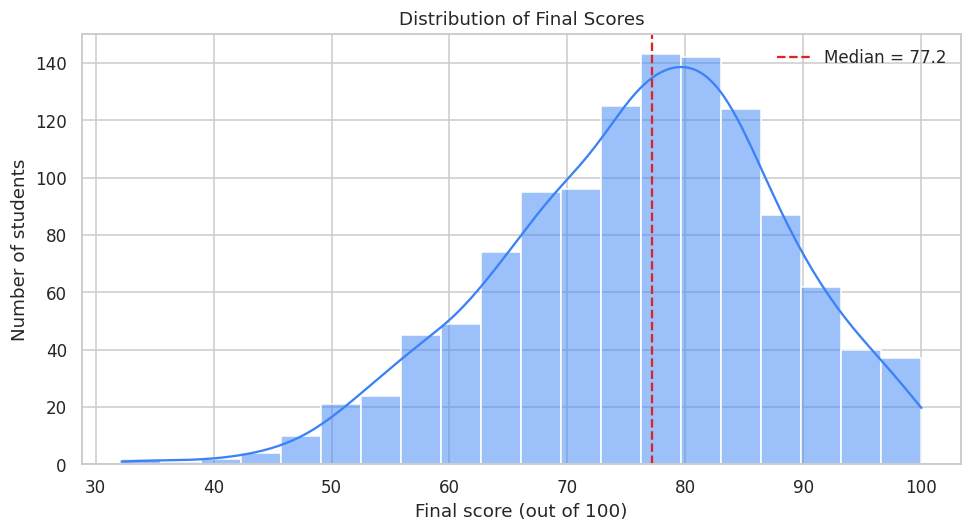

Interpretation: The mean final score is 76.2, the median is 77.2, and the standard deviation is 11.8. The histogram shows how scores are spread across the simulated cohort; review the tails for low/high-score groups needing further investigation.


In [6]:
# Chart 1: final score distribution (distribution graph)
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=clean_df, x="final_score", bins=20, kde=True, color="#3B82F6", ax=ax)
ax.axvline(clean_df["final_score"].median(), color="#DC2626", linestyle="--", label=f"Median = {clean_df['final_score'].median():.1f}")
ax.set(title="Distribution of Final Scores", xlabel="Final score (out of 100)", ylabel="Number of students")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHART_DIR / "score-distribution.png", bbox_inches="tight")
plt.show()
print(f"Interpretation: The mean final score is {clean_df['final_score'].mean():.1f}, the median is {clean_df['final_score'].median():.1f}, and the standard deviation is {clean_df['final_score'].std():.1f}. The histogram shows how scores are spread across the simulated cohort; review the tails for low/high-score groups needing further investigation.")

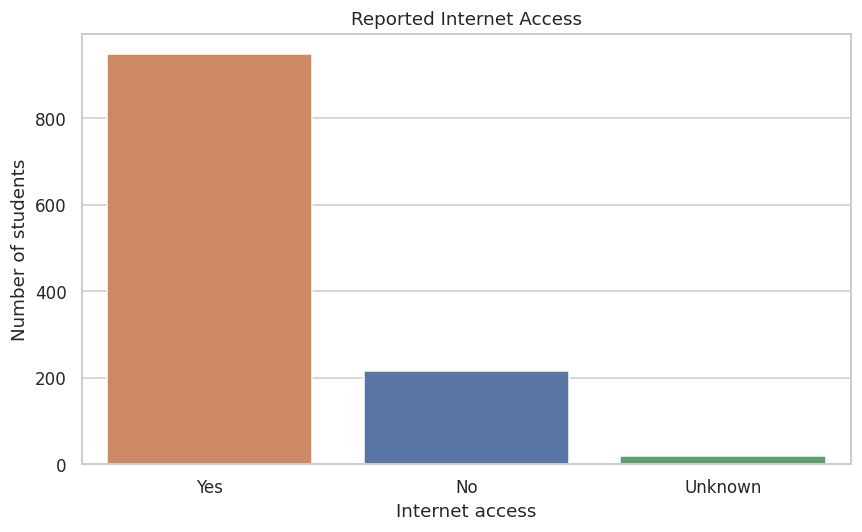

Interpretation: The count plot displays the number of records in each internet-access category. The largest category is Yes (80.1%). Unknown responses should be treated as a data-quality follow-up, not as evidence that students lack access.


In [7]:
# Chart 2: category representation (comparison/count graph)
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=clean_df, x="internet_access", order=clean_df["internet_access"].value_counts().index, hue="internet_access", legend=False, ax=ax)
ax.set(title="Reported Internet Access", xlabel="Internet access", ylabel="Number of students")
fig.tight_layout()
fig.savefig(CHART_DIR / "internet-access-count.png", bbox_inches="tight")
plt.show()
internet_pct = clean_df["internet_access"].value_counts(normalize=True).mul(100).round(1)
print("Interpretation: The count plot displays the number of records in each internet-access category. The largest category is " + str(internet_pct.index[0]) + f" ({internet_pct.iloc[0]:.1f}%). Unknown responses should be treated as a data-quality follow-up, not as evidence that students lack access.")

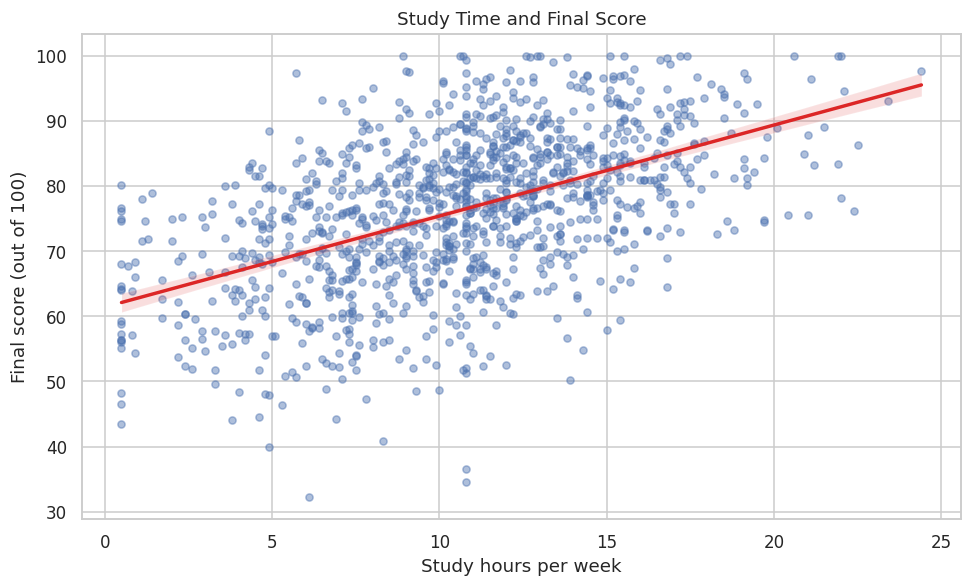

Interpretation: Pearson correlation between study hours and final score is 0.51. This indicates a positive linear association in this simulated sample. Individual outcomes vary, and correlation does not prove that additional study time alone causes higher marks.


In [8]:
# Chart 3: study hours and final score (relationship graph)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.regplot(data=clean_df, x="study_hours_per_week", y="final_score", scatter_kws={"alpha": 0.45, "s": 22}, line_kws={"color": "#DC2626"}, ax=ax)
ax.set(title="Study Time and Final Score", xlabel="Study hours per week", ylabel="Final score (out of 100)")
fig.tight_layout()
fig.savefig(CHART_DIR / "study-hours-vs-final-score.png", bbox_inches="tight")
plt.show()
study_corr = clean_df["study_hours_per_week"].corr(clean_df["final_score"])
print(f"Interpretation: Pearson correlation between study hours and final score is {study_corr:.2f}. This indicates a {('positive' if study_corr > 0.1 else 'negative' if study_corr < -0.1 else 'weak/near-zero')} linear association in this simulated sample. Individual outcomes vary, and correlation does not prove that additional study time alone causes higher marks.")

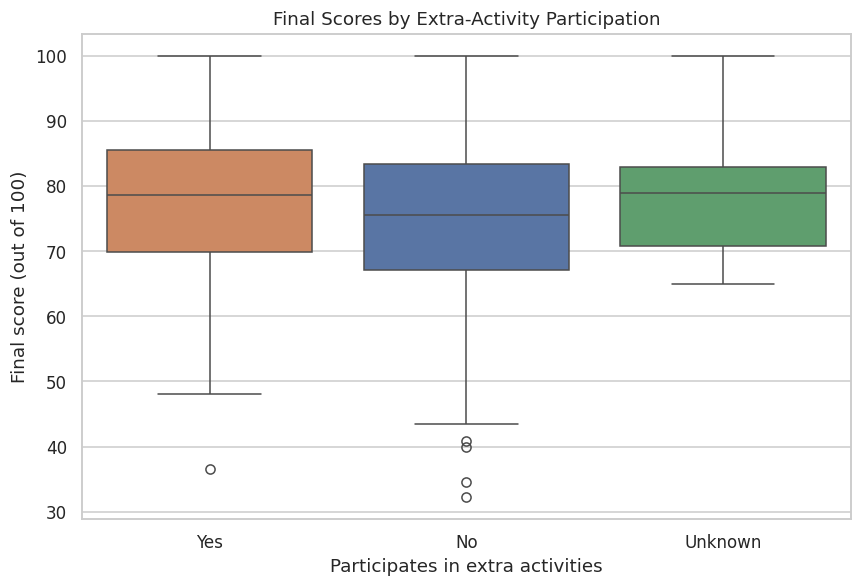

,count,mean,median
extra_activities,,,
No,556,74.54,75.55
Unknown,22,78.16,78.90
Yes,605,77.69,78.60


Interpretation: The mean-score difference (Yes minus No) is 3.15 points. The box plot also shows within-group spread and outliers; the difference is descriptive and cannot be attributed to activity participation alone.


In [9]:
# Chart 4: compare scores by extra activities (box plot)
fig, ax = plt.subplots(figsize=(8, 5.5))
order = [x for x in ["Yes", "No", "Unknown"] if x in set(clean_df["extra_activities"])]
sns.boxplot(data=clean_df, x="extra_activities", y="final_score", order=order, hue="extra_activities", legend=False, ax=ax)
ax.set(title="Final Scores by Extra-Activity Participation", xlabel="Participates in extra activities", ylabel="Final score (out of 100)")
fig.tight_layout()
fig.savefig(CHART_DIR / "activities-vs-final-score.png", bbox_inches="tight")
plt.show()
activity_stats = clean_df.groupby("extra_activities", observed=False)["final_score"].agg(["count", "mean", "median"]).round(2)
display(activity_stats)
if {"Yes", "No"}.issubset(set(activity_stats.index)):
    gap = activity_stats.loc["Yes", "mean"] - activity_stats.loc["No", "mean"]
    print(f"Interpretation: The mean-score difference (Yes minus No) is {gap:.2f} points. The box plot also shows within-group spread and outliers; the difference is descriptive and cannot be attributed to activity participation alone.")
else:
    print("Interpretation: Compare the medians, spread, and outliers for the displayed groups. This is descriptive only.")

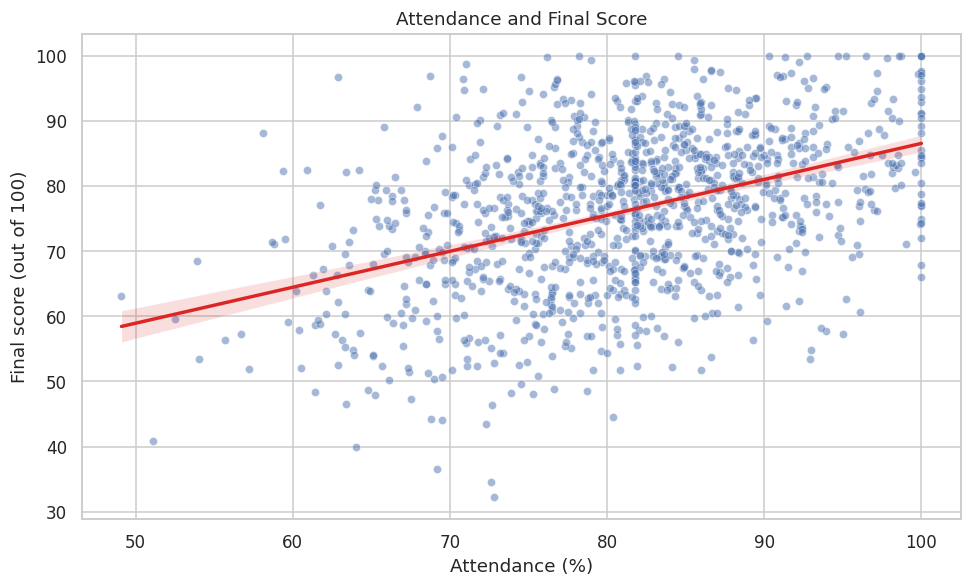

Interpretation: Pearson correlation between attendance and final score is 0.43. The upward/downward direction and scatter indicate the strength and consistency of the linear pattern. This simulated relationship should be verified on real records before decisions are made.


In [10]:
# Chart 5: attendance vs final score (second relationship view)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=clean_df, x="attendance_pct", y="final_score", alpha=0.5, s=28, ax=ax)
sns.regplot(data=clean_df, x="attendance_pct", y="final_score", scatter=False, color="#DC2626", ax=ax)
ax.set(title="Attendance and Final Score", xlabel="Attendance (%)", ylabel="Final score (out of 100)")
fig.tight_layout()
fig.savefig(CHART_DIR / "attendance-vs-final-score.png", bbox_inches="tight")
plt.show()
attendance_corr = clean_df["attendance_pct"].corr(clean_df["final_score"])
print(f"Interpretation: Pearson correlation between attendance and final score is {attendance_corr:.2f}. The upward/downward direction and scatter indicate the strength and consistency of the linear pattern. This simulated relationship should be verified on real records before decisions are made.")

,age,attendance_pct,study_hours_per_week,assignment_score,midterm_score,final_score
age,1.00,-0.00,-0.00,0.02,-0.02,0.02
attendance_pct,-0.00,1.00,0.17,0.41,0.40,0.43
study_hours_per_week,-0.00,0.17,1.00,0.46,0.55,0.51
assignment_score,0.02,0.41,0.46,1.00,0.67,0.70
midterm_score,-0.02,0.40,0.55,0.67,1.00,0.74
final_score,0.02,0.43,0.51,0.70,0.74,1.00


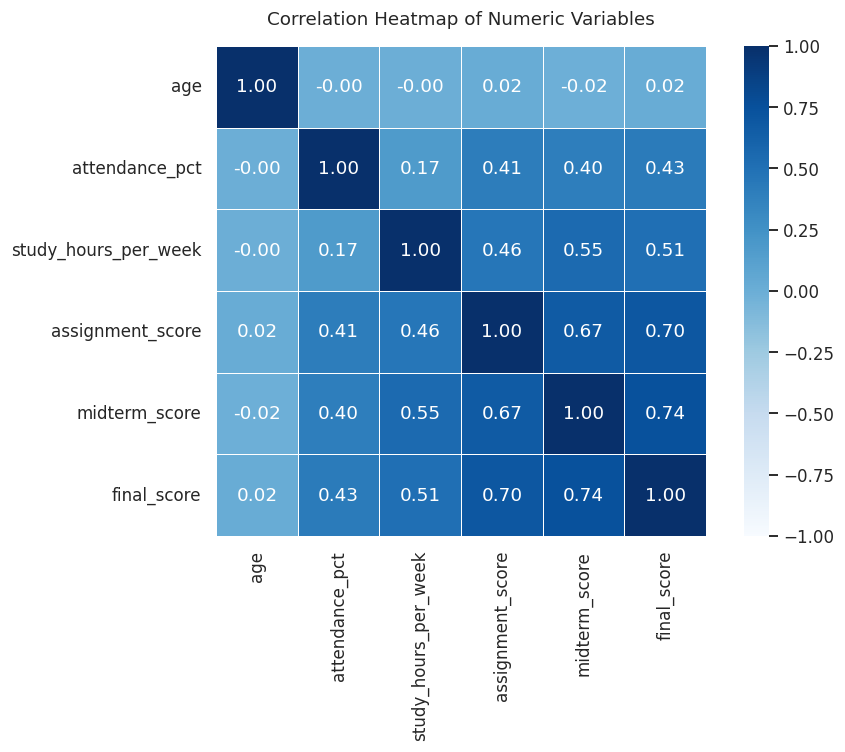

Strongest absolute numeric relationship:
midterm_score and final_score: r = 0.74
Interpretation: Correlations near +1 indicate strong positive linear association, near -1 strong negative linear association, and near 0 weak linear association. Correlation does not establish causation and may not capture non-linear relationships.


In [11]:
# Chart 6: correlation heatmap for numerical columns (correlation analysis)
numeric_for_corr = clean_df.select_dtypes(include="number").drop(columns=["student_id"], errors="ignore")
corr = numeric_for_corr.corr()
display(corr.round(2))
corr.to_csv(TABLE_DIR / "correlation_matrix.csv")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Variables", pad=14)
fig.tight_layout()
fig.savefig(CHART_DIR / "correlation-heatmap.png", bbox_inches="tight")
plt.show()

# Find strongest off-diagonal pairs without listing both A-B and B-A.
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(key=lambda s: s.abs(), ascending=False)
print("Strongest absolute numeric relationship:")
if not pairs.empty:
    (var_a, var_b), value = pairs.index[0], pairs.iloc[0]
    print(f"{var_a} and {var_b}: r = {value:.2f}")
print("Interpretation: Correlations near +1 indicate strong positive linear association, near -1 strong negative linear association, and near 0 weak linear association. Correlation does not establish causation and may not capture non-linear relationships.")

## 6. Evidence-based observations (5-8)
These observations are computed from the cleaned simulated data. Do not report these numbers as findings about real students.

In [12]:
# Construct concise, reproducible observations from the cleaned values.
score_mean = clean_df["final_score"].mean()
score_median = clean_df["final_score"].median()
score_std = clean_df["final_score"].std()
study_corr = clean_df["study_hours_per_week"].corr(clean_df["final_score"])
attendance_corr = clean_df["attendance_pct"].corr(clean_df["final_score"])
assignment_corr = clean_df["assignment_score"].corr(clean_df["final_score"])
midterm_corr = clean_df["midterm_score"].corr(clean_df["final_score"])
unknown_internet_pct = (clean_df["internet_access"] == "Unknown").mean()*100
low_attendance_pct = (clean_df["attendance_pct"] < 75).mean()*100
below_50_pct = (clean_df["final_score"] < 50).mean()*100
activity_means = clean_df.groupby("extra_activities")["final_score"].mean()
activity_gap = float(activity_means.get("Yes", np.nan) - activity_means.get("No", np.nan))

observations = [
    f"The cleaned dataset contains {len(clean_df):,} records. Final scores average {score_mean:.1f}/100 (median {score_median:.1f}; standard deviation {score_std:.1f}).",
    f"Study hours and final score have a Pearson correlation of r = {study_corr:.2f}, a {'positive' if study_corr > 0 else 'negative' if study_corr < 0 else 'near-zero'} linear association in this simulated sample.",
    f"Attendance and final score have a Pearson correlation of r = {attendance_corr:.2f}; this is descriptive and does not show that attendance alone causes a score change.",
    f"Assignment score and final score have a Pearson correlation of r = {assignment_corr:.2f}.",
    f"Midterm score and final score have a Pearson correlation of r = {midterm_corr:.2f}.",
    f"{low_attendance_pct:.1f}% of cleaned records have attendance below 75%; this threshold is an illustrative monitoring flag, not a validated intervention cut-off.",
    f"{below_50_pct:.1f}% of cleaned records have final scores below 50/100; these records could be reviewed as a group in a real pilot, with safeguards and context.",
    f"{unknown_internet_pct:.1f}% of records have internet access recorded as Unknown after cleaning, indicating a need to improve response completeness."
]
for i, item in enumerate(observations, start=1):
    print(f"{i}. {item}")
(TABLE_DIR / "key_observations.txt").write_text("\n".join(f"{i}. {x}" for i,x in enumerate(observations, start=1)), encoding="utf-8")
with open(TABLE_DIR / "analysis_metrics.json", "w", encoding="utf-8") as f:
    json.dump({"raw_rows": rows_raw, "clean_rows": int(len(clean_df)), "raw_columns": int(raw_df.shape[1]), "duplicates_removed": int(rows_raw-rows_after_duplicate_removal), "target_rows_dropped": int(missing_target_rows), "final_mean": float(score_mean), "final_median": float(score_median), "final_std": float(score_std), "study_final_corr": float(study_corr), "attendance_final_corr": float(attendance_corr), "assignment_final_corr": float(assignment_corr), "midterm_final_corr": float(midterm_corr), "low_attendance_pct": float(low_attendance_pct), "below_50_pct": float(below_50_pct), "unknown_internet_pct": float(unknown_internet_pct), "activity_mean_gap_yes_minus_no": float(activity_gap)}, f, indent=2)
print("\nSaved observations and metrics to outputs/tables/.")

1. The cleaned dataset contains 1,183 records. Final scores average 76.2/100 (median 77.2; standard deviation 11.8).
2. Study hours and final score have a Pearson correlation of r = 0.51, a positive linear association in this simulated sample.
3. Attendance and final score have a Pearson correlation of r = 0.43; this is descriptive and does not show that attendance alone causes a score change.
4. Assignment score and final score have a Pearson correlation of r = 0.70.
5. Midterm score and final score have a Pearson correlation of r = 0.74.
6. 23.3% of cleaned records have attendance below 75%; this threshold is an illustrative monitoring flag, not a validated intervention cut-off.
7. 1.7% of cleaned records have final scores below 50/100; these records could be reviewed as a group in a real pilot, with safeguards and context.
8. 1.6% of records have internet access recorded as Unknown after cleaning, indicating a need to improve response completeness.

Saved observations and metrics to

## 7. Business interpretation and recommendations
The following are cautious recommendations for a real institution to **test**, not proven interventions. Real data, consent, fairness review, and educator input would be required before operational use.

In [13]:
recommendations = [
    "Pilot an early-support review for students with repeated low attendance or falling assessment scores; use human review rather than an automated label.",
    "Offer study-planning resources and optional tutoring to students who request help, then evaluate whether the support improves outcomes.",
    "Use assignment and midterm performance as discussion prompts for teachers, while considering course difficulty and grading differences.",
    "Improve completeness of fields such as internet access and parental education, and document why each field is collected.",
    "Validate the patterns on a real, representative dataset and examine differences across groups before adopting thresholds or interventions.",
]
for i, rec in enumerate(recommendations, start=1):
    print(f"{i}. {rec}")
(TABLE_DIR / "recommendations.txt").write_text("\n".join(f"{i}. {x}" for i,x in enumerate(recommendations, start=1)), encoding="utf-8")

1. Pilot an early-support review for students with repeated low attendance or falling assessment scores; use human review rather than an automated label.
2. Offer study-planning resources and optional tutoring to students who request help, then evaluate whether the support improves outcomes.
3. Use assignment and midterm performance as discussion prompts for teachers, while considering course difficulty and grading differences.
4. Improve completeness of fields such as internet access and parental education, and document why each field is collected.
5. Validate the patterns on a real, representative dataset and examine differences across groups before adopting thresholds or interventions.


697

## 8. Limitations and conclusion
- The dataset is simulated; results do not establish facts about a real school or student population.
- Correlation captures linear association and does not prove causation.
- Median imputation can reduce variability; imputed values should be tracked and assessed in real projects.
- Rows without a valid final score were excluded because the outcome should not be fabricated.
- Sensitive demographic and family variables should be minimized, access-controlled, and assessed for fairness before use in any real support process.

**Conclusion:** The project demonstrates the Week 1 workflow end to end: inspect data, document features, clean quality issues, summarize the dataset, create and interpret visualizations, and translate tentative patterns into cautious business recommendations. No ML model is trained because the handbook emphasizes analysis foundations in Week 1.